# 📈 07 - Plotting Basics

Visualization is a core part of data science. A good chart shows in seconds what a table of numbers hides. This notebook introduces **NumPy** (fast numeric arrays) and **Matplotlib** (Python's core plotting library), then walks through the most common chart types and when to use each.

## ✅ Learning Goals
- Create arrays with NumPy and do quick calculations on them
- Import and use `matplotlib.pyplot`, and name the parts of a plot
- Create and label line, bar, scatter, histogram, box, and pie charts
- Put several charts in one figure with subplots, and save a chart to a file
- Choose a chart that fits the question being asked
- Judge a chart's clarity with a quality checklist, and fix a misleading one

## 1. Setup

NumPy and Matplotlib are both in the course's `requirements.txt`, so they should already be in your `.venv`. If an import fails, run `%pip install numpy matplotlib` (see notebook 01).

The standard import names are `np` and `plt`. You'll see them in almost every data science notebook. `%matplotlib inline` tells Jupyter to draw plots right under the cell. Modern Jupyter and VS Code do this by default, but the line is harmless and makes it explicit.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

# Charts you save go here (same pattern as notebooks 05 and 06)
OUT = Path('07-OutputFiles')
OUT.mkdir(exist_ok=True)

### Your First Plot
Almost every Matplotlib chart follows the same pattern: **plot** the data, **label** it, then **show** it.

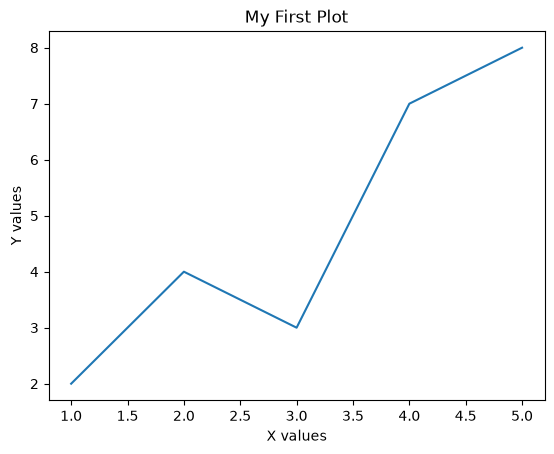

In [2]:
x = np.array([1, 2, 3, 4, 5])
y = np.array([2, 4, 3, 7, 8])

plt.plot(x, y)
plt.xlabel('X values')
plt.ylabel('Y values')
plt.title('My First Plot')
plt.show()

## 2. NumPy Essentials
A NumPy **array** looks like a list, but it's built for numbers. It's much faster, and math applies to **every element at once**, so you don't need a loop.

### Creating Arrays

In [3]:
scores = np.array([82, 91, 76, 88, 95])
temperatures = np.array([68.2, 70.1, 73.5, 71.8])

print(scores)
print(temperatures)

[82 91 76 88 95]
[68.2 70.1 73.5 71.8]


### Math on the Whole Array
This is the big difference from a list. With a list, `[1, 2] * 2` gives `[1, 2, 1, 2]`. With an array, it doubles every value:

In [4]:
print(scores + 5)            # curve every score by 5 points
print(scores * 1.1)          # scale every score by 10%
print(scores >= 85)          # compare every score: an array of True/False
print(scores[scores >= 85])  # keep only the scores that pass

[ 87  96  81  93 100]
[ 90.2 100.1  83.6  96.8 104.5]
[False  True False  True  True]
[91 88 95]


### Generating Values
| Function | Gives you | Example |
|---|---|---|
| `np.arange(start, stop)` | Whole numbers from `start` up to (not including) `stop`, like `range` | `np.arange(1, 8)` → 1 to 7 |
| `np.linspace(start, stop, n)` | `n` evenly spaced values, **including** `stop`. Great for smooth curves | `np.linspace(0, 10, 100)` |
| `np.random.randint(low, high, size=n)` | `n` random whole numbers from `low` up to (not including) `high` | `np.random.randint(50, 101, size=20)` |
| `np.random.normal(mean, sd, size=n)` | `n` random values from a bell curve | `np.random.normal(75, 10, size=200)` |

Random numbers change every time you run the cell. `np.random.seed(some_number)` makes them **repeatable**, which is handy when you want the same "random" data each time.

In [5]:
days = np.arange(1, 8)
values = np.linspace(0, 10, 5)

np.random.seed(42)
random_scores = np.random.randint(50, 101, size=10)

print(days)
print(values)
print(random_scores)

[1 2 3 4 5 6 7]
[ 0.   2.5  5.   7.5 10. ]
[88 78 64 92 57 70 88 68 72 60]


### Useful Calculations

In [6]:
print('mean:  ', np.mean(scores))
print('median:', np.median(scores))
print('min:   ', np.min(scores))
print('max:   ', np.max(scores))
print('sum:   ', np.sum(scores))

mean:   86.4
median: 88.0
min:    76
max:    95
sum:    432


✅ **Your Turn**: Create an array `week_temps` holding temperatures for **seven** days. Print its mean, median, min, and max. Then use a comparison to print only the days warmer than the mean. You'll plot this array in section 4.

In [7]:
# Your turn here
week_temps = np.array([83, 86, 79, 75, 73, 67, 65])

print('mean:  ', np.mean(week_temps))
print('median:', np.median(week_temps))
print('min:   ', np.min(week_temps))
print('max:   ', np.max(week_temps))

print(week_temps[week_temps > np.mean(week_temps)])


mean:   75.42857142857143
median: 75.0
min:    65
max:    86
[83 86 79]


## 3. Anatomy of a Plot
Every chart is built from the same parts:
- **Figure**: the entire visual area, which can hold one chart or several
- **Axes**: the chart itself, the area where data is drawn (not the same thing as an "axis"!)
- **Title**: explains the chart's purpose
- **Axis labels**: explain what's measured, **including units**
- **Legend**: identifies multiple data series
- **Grid**: can improve readability when used lightly

You can also style the data itself with `color`, `marker` (the dot at each point), and `linestyle`:

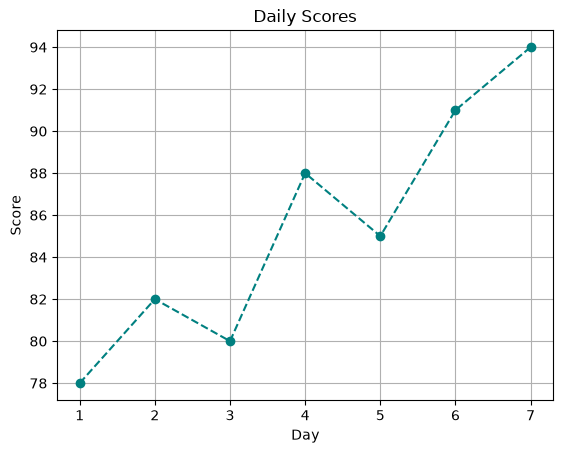

In [8]:
daily_scores = np.array([78, 82, 80, 88, 85, 91, 94])

plt.plot(days, daily_scores, color='teal', marker='o', linestyle='--')
plt.title('Daily Scores')
plt.xlabel('Day')
plt.ylabel('Score')
plt.grid(True)
plt.show()

| Option | Some values to try |
|---|---|
| `color` | `'teal'`, `'navy'`, `'darkorange'`, or a hex code like `'#1f77b4'` |
| `marker` | `'o'` circle, `'s'` square, `'^'` triangle, `'x'` |
| `linestyle` | `'-'` solid, `'--'` dashed, `':'` dotted, `'-.'` dash-dot |

Two lines on one chart need a `label` each, plus `plt.legend()`:

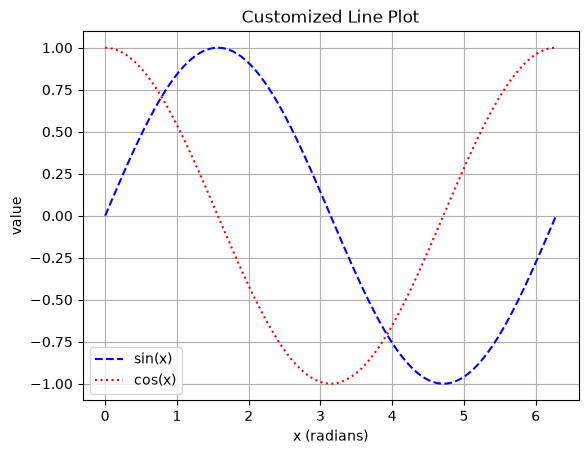

In [9]:
x = np.linspace(0, 2 * np.pi, 100)
y1 = np.sin(x)
y2 = np.cos(x)

plt.plot(x, y1, label='sin(x)', linestyle='--', color='blue')
plt.plot(x, y2, label='cos(x)', linestyle=':', color='red')
plt.title('Customized Line Plot')
plt.xlabel('x (radians)')
plt.ylabel('value')
plt.legend()
plt.grid(True)
plt.show()

✅ **Your Turn**: Customize your own plot with labels, a legend, and grid lines.

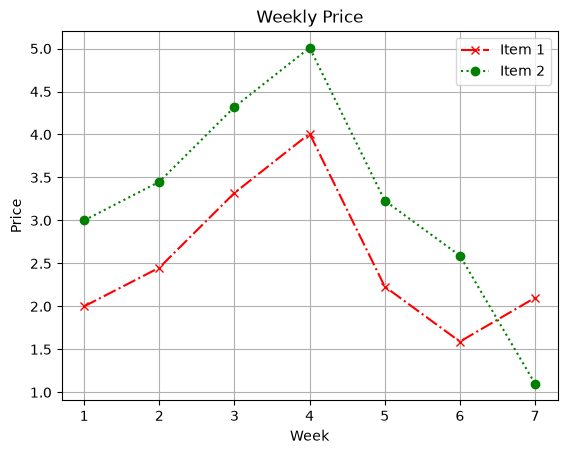

In [10]:
# Your turn here
weeks = np.arange(1, 8)
weekly_price1 = np.array([2.00, 2.45, 3.32, 4.01, 2.23, 1.59, 2.10])
weekly_price2 = np.array([3.00, 3.45, 4.32, 5.01, 3.23, 2.59, 1.10])

plt.plot(weeks, weekly_price1, label='Item 1', color='red', marker='x', linestyle='-.')
plt.plot(weeks, weekly_price2, label='Item 2', color='green', marker='o', linestyle=':')

plt.title('Weekly Price')
plt.xlabel('Week')
plt.ylabel('Price')
plt.legend()
plt.grid(True)
plt.show()


## 4. Line Plots
**Best for:** change over an ordered value, especially **time**. The line connecting the points says "these values are connected in order".

A smooth curve is just many points close together. `np.linspace` makes 100 of them:

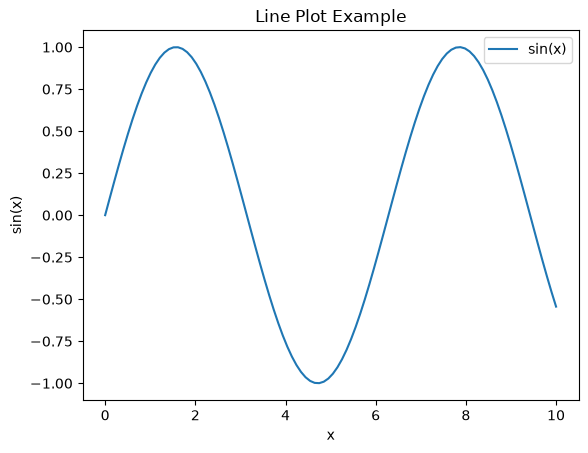

In [11]:
x = np.linspace(0, 10, 100)
y = np.sin(x)

plt.plot(x, y, label='sin(x)')
plt.title('Line Plot Example')
plt.xlabel('x')
plt.ylabel('sin(x)')
plt.legend()
plt.show()

Line plots work with text labels on the x-axis too:

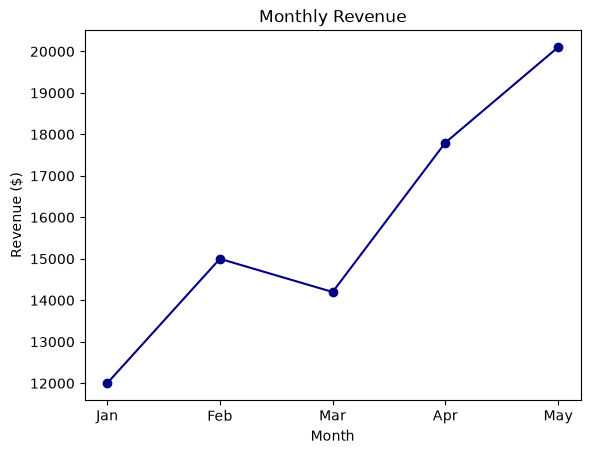

In [12]:
months = np.array(['Jan', 'Feb', 'Mar', 'Apr', 'May'])
revenue = np.array([12000, 15000, 14200, 17800, 20100])

plt.plot(months, revenue, marker='o', color='navy')
plt.title('Monthly Revenue')
plt.xlabel('Month')
plt.ylabel('Revenue ($)')
plt.show()

### Multiple Lines

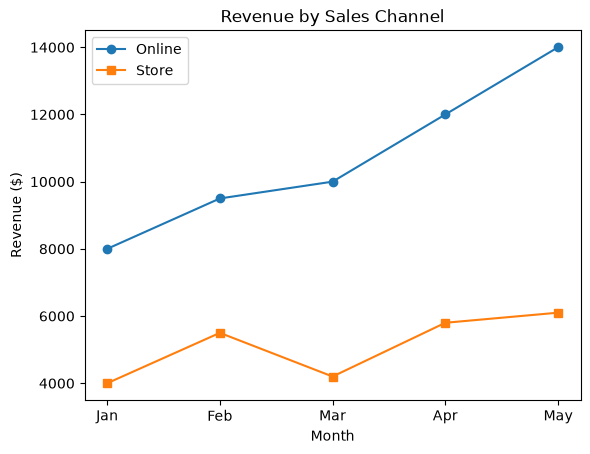

In [13]:
online = np.array([8000, 9500, 10000, 12000, 14000])
store = np.array([4000, 5500, 4200, 5800, 6100])

plt.plot(months, online, marker='o', label='Online')
plt.plot(months, store, marker='s', label='Store')
plt.title('Revenue by Sales Channel')
plt.xlabel('Month')
plt.ylabel('Revenue ($)')
plt.legend()
plt.show()

✅ **Your Turn**:
1. Re-create the `sin(x)` plot above and add `cos(x)` on the same graph, with a different color and label.
2. Make a line chart of your `week_temps` array from section 2, with days 1–7 on the x-axis. Give it a title and labeled axes, including units.

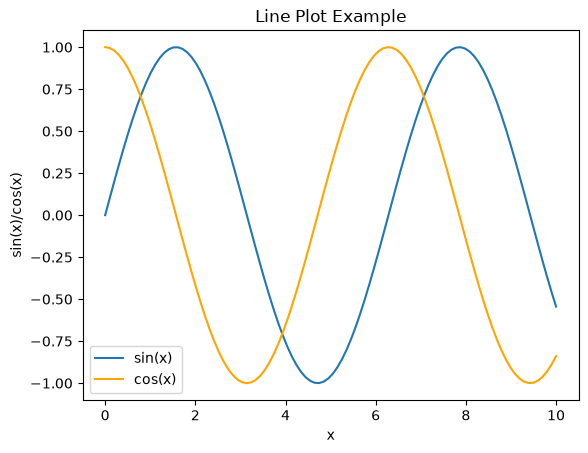

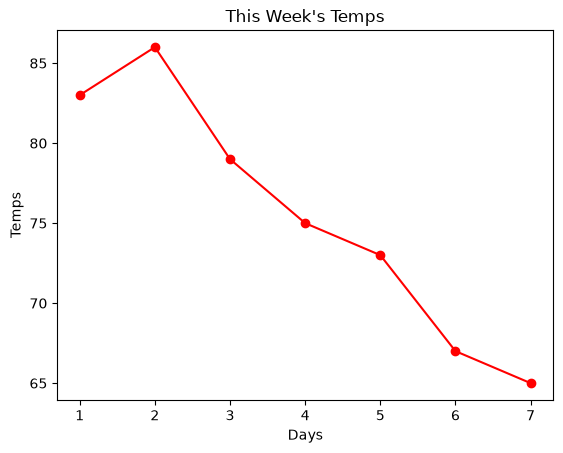

In [14]:
# Your turn here
x = np.linspace(0, 10, 100)
y = np.sin(x)
z = np.cos(x)

plt.plot(x, y, label='sin(x)')
plt.plot(x, z, label='cos(x)', color='orange')
plt.title('Line Plot Example')
plt.xlabel('x')
plt.ylabel('sin(x)/cos(x)')
plt.legend()
plt.show()

# week_temps chart
days = np.array([1, 2, 3, 4, 5, 6, 7])

plt.plot(days, week_temps, marker='o', color='red')
plt.title('This Week\'s Temps')
plt.xlabel('Days')
plt.ylabel('Temps')
plt.show()



## 5. Bar Charts
**Best for:** comparing separate **categories**. Unlike a line plot, the order of the bars doesn't imply a connection.

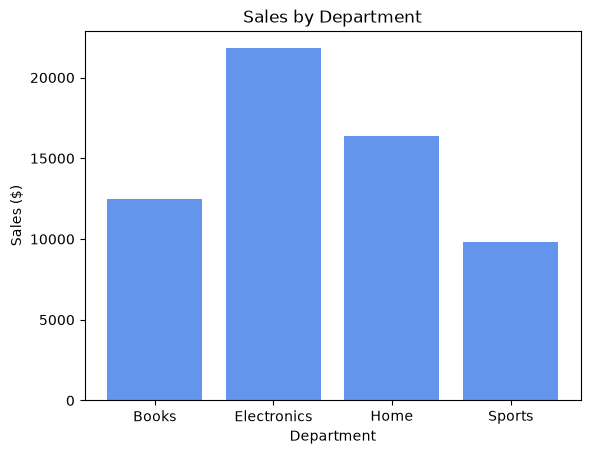

In [15]:
departments = np.array(['Books', 'Electronics', 'Home', 'Sports'])
sales = np.array([12500, 21800, 16400, 9800])

plt.bar(departments, sales, color='cornflowerblue')
plt.title('Sales by Department')
plt.xlabel('Department')
plt.ylabel('Sales ($)')
plt.show()

### Horizontal Bars
Use `plt.barh` when the category labels are long, so they don't overlap:

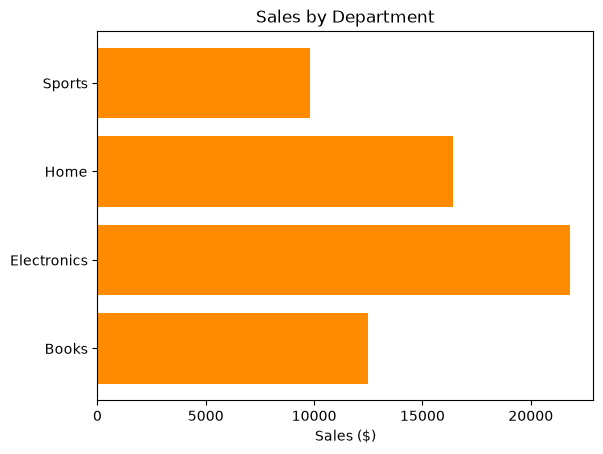

In [16]:
plt.barh(departments, sales, color='darkorange')
plt.title('Sales by Department')
plt.xlabel('Sales ($)')
plt.show()

### Grouped Bars
To put two bars side by side for each category, place the categories at the positions 0, 1, 2, ... (`np.arange`). Then shift one set of bars half a bar-width **left** and the other half a width **right**. `plt.xticks` puts the category names back under each group:

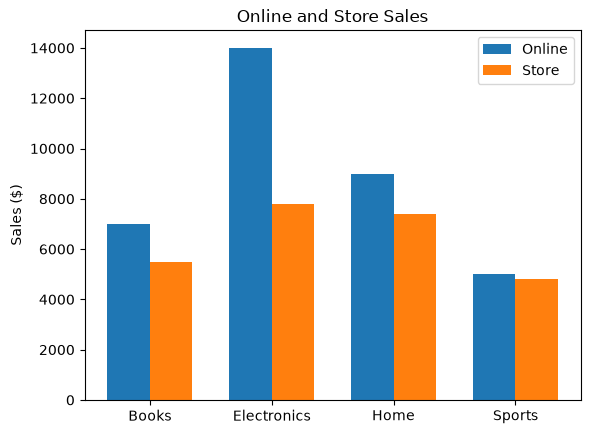

In [17]:
x = np.arange(len(departments))
online_sales = np.array([7000, 14000, 9000, 5000])
store_sales = np.array([5500, 7800, 7400, 4800])
width = 0.35

plt.bar(x - width / 2, online_sales, width, label='Online')
plt.bar(x + width / 2, store_sales, width, label='Store')
plt.xticks(x, departments)
plt.ylabel('Sales ($)')
plt.title('Online and Store Sales')
plt.legend()
plt.show()

✅ **Your Turn**:
1. Create your own bar chart with at least 4 categories (e.g. favorite foods, courses, or hobbies).
2. Make a **grouped** bar chart comparing online and in-store sales for 4 months, using made-up numbers.

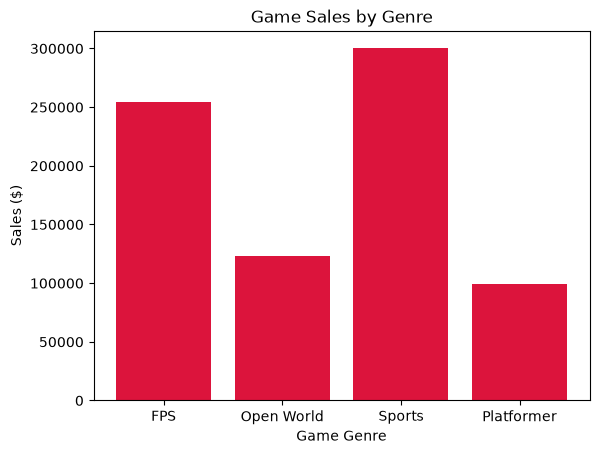

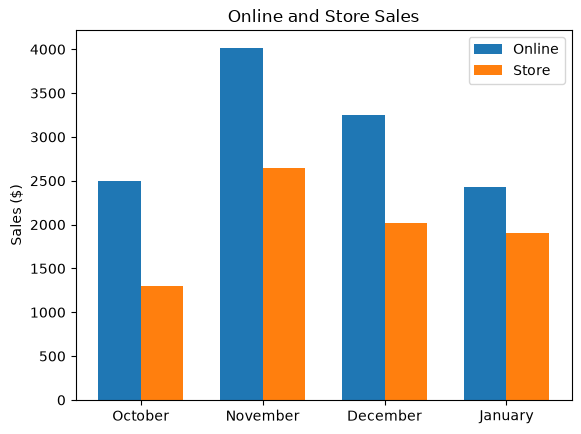

In [18]:
#1
game_genres = np.array(['FPS', 'Open World', 'Sports', 'Platformer'])
sales = np.array([254000, 123000, 300000, 98970])

plt.bar(game_genres, sales, color='crimson')
plt.title('Game Sales by Genre')
plt.xlabel('Game Genre')
plt.ylabel('Sales ($)')
plt.show()

#2
my_months = np.array(['October', 'November', 'December', 'January'])
x = np.arange(len(my_months))
online_sales = np.array([2500, 4015, 3250, 2430])
store_sales = np.array([1300, 2645, 2015, 1900])
width = 0.35

plt.bar(x - width / 2, online_sales, width, label='Online')
plt.bar(x + width / 2, store_sales, width, label='Store')
plt.xticks(x, my_months)
plt.ylabel('Sales ($)')
plt.title('Online and Store Sales')
plt.legend()
plt.show()

## 6. Scatter Plots
**Best for:** investigating a **relationship** between two numeric variables. Each dot is one observation, and there's no connecting line because the points aren't in a sequence.

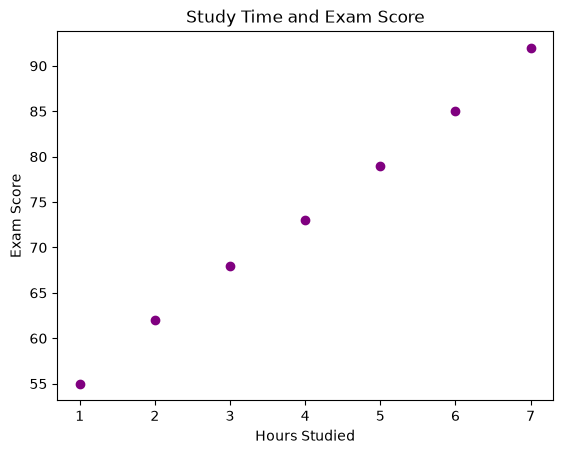

In [19]:
hours_studied = np.array([1, 2, 3, 4, 5, 6, 7])
exam_scores = np.array([55, 62, 68, 73, 79, 85, 92])

plt.scatter(hours_studied, exam_scores, color='purple')
plt.title('Study Time and Exam Score')
plt.xlabel('Hours Studied')
plt.ylabel('Exam Score')
plt.show()

Look for the overall direction:
- **Positive**: one goes up as the other goes up (like the chart above)
- **Negative**: one goes down as the other goes up
- **Unclear / none**: no pattern, just a cloud

⚠️ A relationship isn't proof that one thing **causes** the other.

### A Third Variable with Color and Size
`c=` colors each dot by a value, and `s=` sizes it. `cmap` picks the color scale, and `alpha` makes the dots see-through so overlaps stay visible:

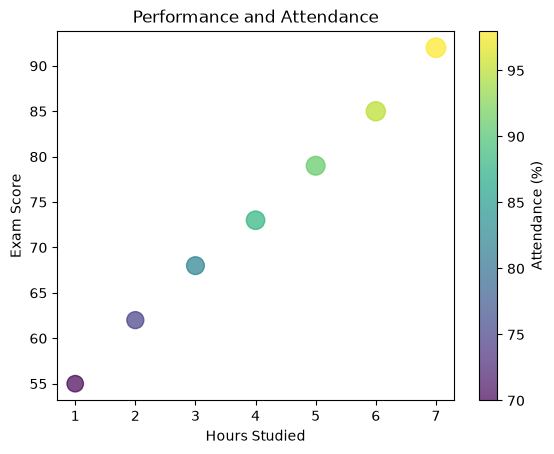

In [20]:
attendance = np.array([70, 75, 82, 88, 91, 95, 98])

plt.scatter(hours_studied, exam_scores, s=attendance * 2,
            c=attendance, cmap='viridis', alpha=0.7)
plt.colorbar(label='Attendance (%)')
plt.xlabel('Hours Studied')
plt.ylabel('Exam Score')
plt.title('Performance and Attendance')
plt.show()

✅ **Your Turn**:
1. Generate two sets of 30 random points each (`np.random.rand(30)` gives values between 0 and 1) and plot them in different colors on the same scatter plot, with a legend.
2. Make up arrays for a product's **price** and **units sold** (8 values each) where higher prices sell fewer units. Plot them, then write a comment saying whether the relationship is positive, negative, or unclear.

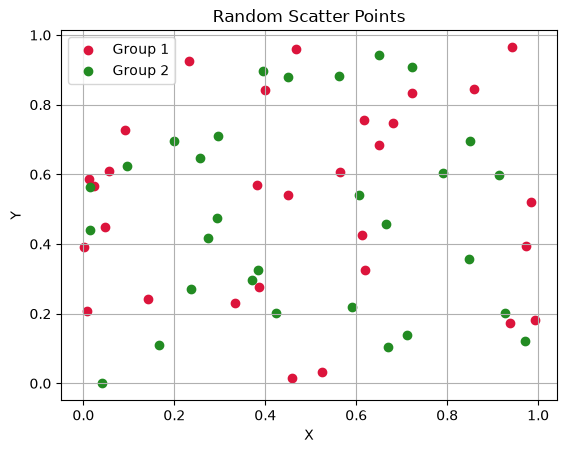

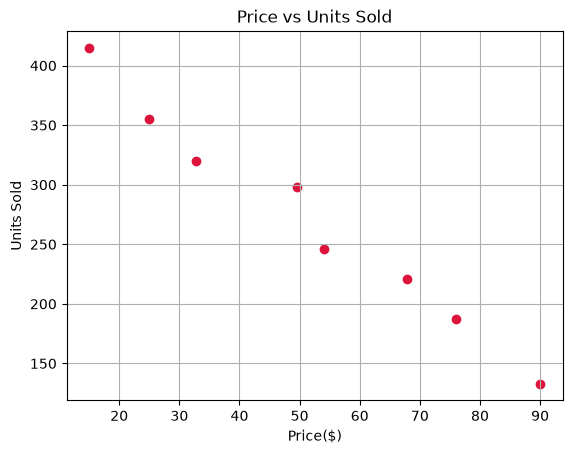

In [21]:
#1
x1 = np.random.rand(30)
y1 = np.random.rand(30)

x2 = np.random.rand(30)
y2 = np.random.rand(30)

plt.scatter(x1, y1, color='crimson', label='Group 1')
plt.scatter(x2, y2, color='forestgreen', label='Group 2')

plt.title('Random Scatter Points')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.grid(True)
plt.show()

#2 - Negative relationship
price = np.array([15.00, 24.99, 32.83, 49.52, 53.99, 67.83, 76.00, 89.99]) 
units_sold = np.array([415, 355, 320, 298, 246, 221, 187, 133])

plt.scatter(price, units_sold, color='crimson')
plt.title('Price vs Units Sold')
plt.xlabel('Price($)')
plt.ylabel('Units Sold')
plt.grid(True)
plt.show()


## 7. Histograms
**Best for:** showing the **distribution** of one numeric variable: where the values cluster, how spread out they are, and whether the shape is lopsided.

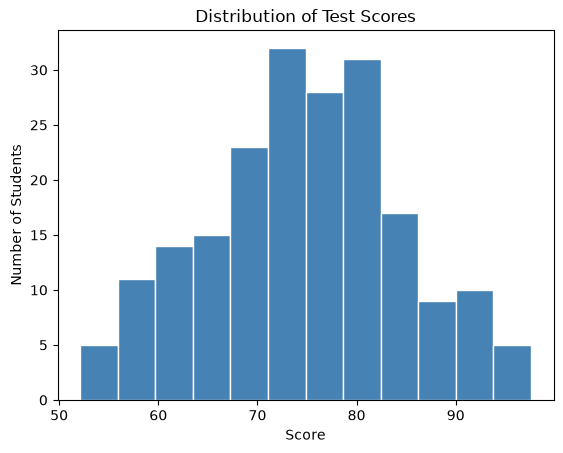

In [22]:
np.random.seed(7)
test_scores = np.random.normal(loc=75, scale=10, size=200)

plt.hist(test_scores, bins=12, color='steelblue', edgecolor='white')
plt.title('Distribution of Test Scores')
plt.xlabel('Score')
plt.ylabel('Number of Students')
plt.show()

- A histogram groups **numeric** values into ranges called **bins**. A bar chart compares **categories**. They look alike, but they answer different questions.
- **The number of bins changes the apparent shape.** Too few bins hide detail, and too many make noise. Compare these with the chart above:

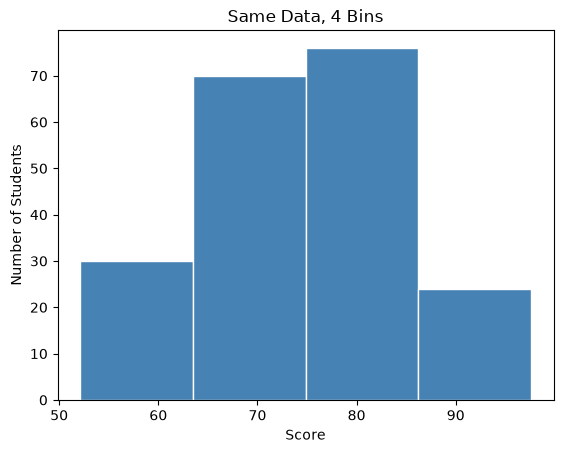

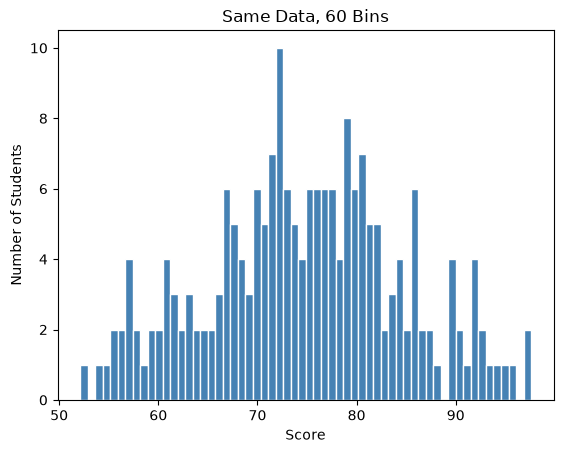

In [23]:
plt.hist(test_scores, bins=4, color='steelblue', edgecolor='white')
plt.title('Same Data, 4 Bins')
plt.xlabel('Score')
plt.ylabel('Number of Students')
plt.show()

plt.hist(test_scores, bins=60, color='steelblue', edgecolor='white')
plt.title('Same Data, 60 Bins')
plt.xlabel('Score')
plt.ylabel('Number of Students')
plt.show()

### Marking the Mean
`plt.axvline` draws a **v**ertical line across the whole chart (`plt.axhline` draws a horizontal one). It's a good way to mark a summary statistic:

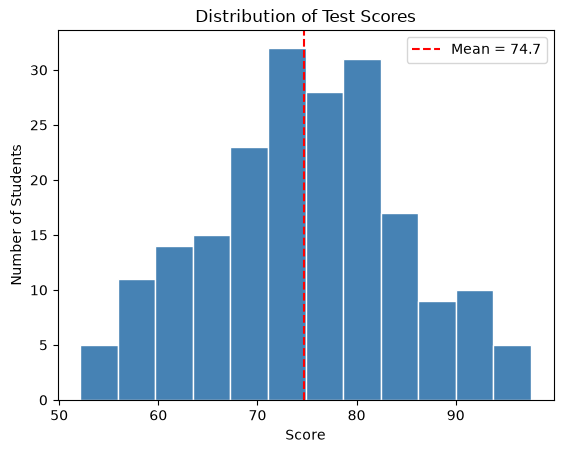

In [24]:
mean_score = np.mean(test_scores)

plt.hist(test_scores, bins=12, color='steelblue', edgecolor='white')
plt.axvline(mean_score, color='red', linestyle='--', label=f'Mean = {mean_score:.1f}')
plt.title('Distribution of Test Scores')
plt.xlabel('Score')
plt.ylabel('Number of Students')
plt.legend()
plt.show()

✅ **Your Turn**: Generate 100 random integers between 0 and 100. Plot a histogram, mark the **median** with a vertical line, and write a comment describing the distribution. Is it roughly flat, bell-shaped, or lopsided? Then compare it to `np.random.normal(50, 15, size=100)`.

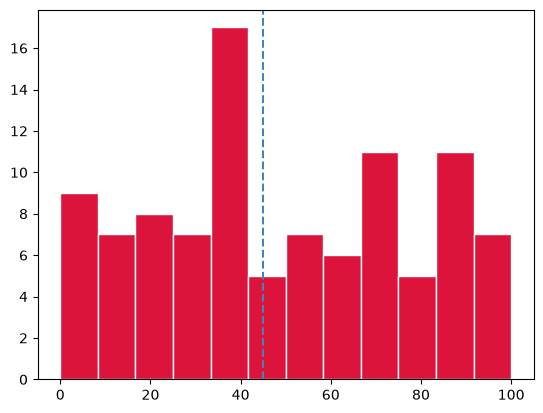

In [25]:
# Your turn here
data = np.random.randint(0, 101, size=100)
median_value = np.median(data)

plt.hist(data, bins=12, color='crimson', edgecolor='white')
plt.axvline(median_value, color='steelblue', linestyle='--', label=f'Median = {median_value:.1f}')
# Initial Distribution = lopsided

# data2 = np.random.normal(50, 15, size=100)
# median_value2 = np.median(data2)
# plt.hist(data2, bins=12, color='steelblue', edgecolor='white')
# plt.axvline(median_value2, color='Crimson', linestyle='--', label=f'Median = {median_value:.1f}')
# Initial Distribution = Bell shaped


## 8. Box Plots
**Best for:** comparing distributions **side by side** and spotting possible **outliers**.

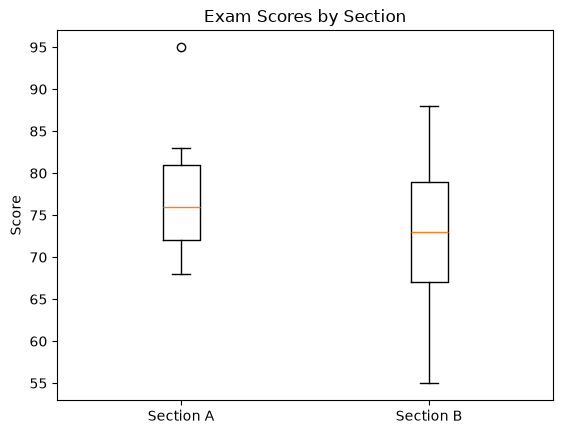

In [26]:
section_a = np.array([68, 70, 72, 75, 76, 78, 81, 83, 95])
section_b = np.array([55, 62, 67, 71, 73, 75, 79, 82, 88])

plt.boxplot([section_a, section_b], tick_labels=['Section A', 'Section B'])
plt.title('Exam Scores by Section')
plt.ylabel('Score')
plt.show()

How to read a box plot:
- **The line inside the box** is the **median**, the middle value.
- **The box** runs from the 1st quartile (25% of values are below it) to the 3rd quartile (75% are below it). It holds the middle half of the data, and its height is the **interquartile range (IQR)**.
- **The whiskers** reach out to the most extreme values that are still within 1.5 × IQR of the box.
- **Dots beyond the whiskers** are **possible outliers**, worth a second look. Section A's 95 is one.

A taller box and longer whiskers mean more **spread** (variability). Module 07 covers these statistics in depth.

💡 If you get an error about `tick_labels`, your Matplotlib is older than version 3.9. Use `labels=` instead.

✅ **Your Turn**: Create quiz scores for **three** class sections (8–10 scores each) and draw them as a box plot. In a comment, say which section has the highest median and which looks the most variable.

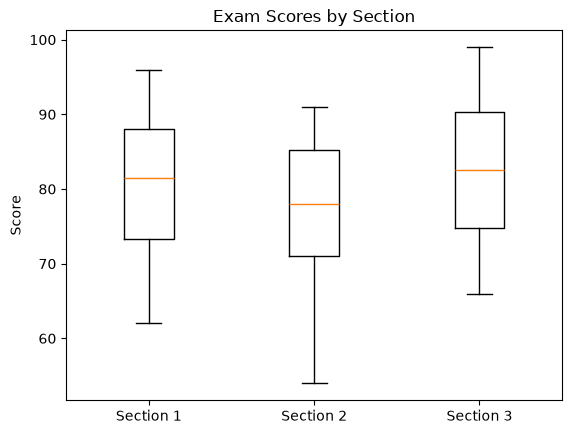

In [27]:
# Your turn here
section_1 = np.array([62, 68, 75, 79, 84, 87, 91, 96])
section_2 = np.array([54, 65, 73, 76, 80, 84, 89, 91])
section_3 = np.array([66, 71, 76, 80, 85, 89, 94, 99])

plt.boxplot([section_1, section_2, section_3], tick_labels=['Section 1', 'Section 2', 'Section 3'])
plt.title('Exam Scores by Section')
plt.ylabel('Score')
plt.show()

# Section 3 has the highest median, Section 2 looks the most variable

## 9. Pie Charts: Use Sparingly
A pie chart shows **parts of one whole**. `autopct` prints each slice's percentage.

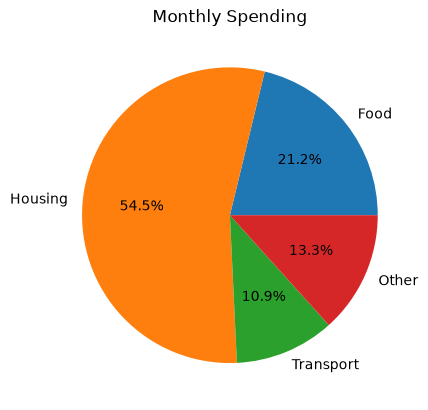

In [28]:
categories = ['Food', 'Housing', 'Transport', 'Other']
spending = [350, 900, 180, 220]

plt.pie(spending, labels=categories, autopct='%1.1f%%')
plt.title('Monthly Spending')
plt.show()

Use a pie chart only for a **small** number of categories that add up to one whole. People judge lengths more accurately than angles, so a bar chart of the same data is usually easier to compare. Which is bigger, Transport or Other? Compare the pie above with this bar chart:

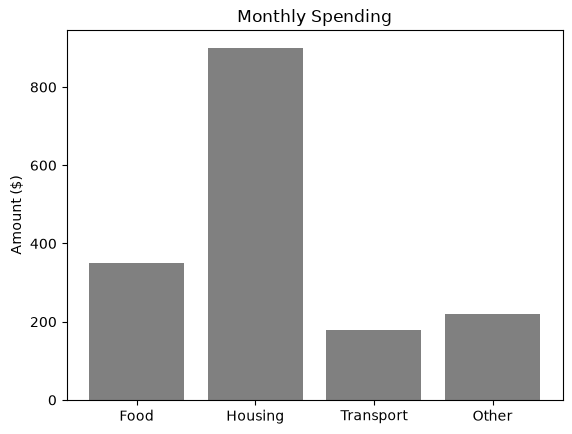

In [29]:
plt.bar(categories, spending, color='gray')
plt.title('Monthly Spending')
plt.ylabel('Amount ($)')
plt.show()

## 10. Subplots
Use **subplots** to put related charts side by side in one figure. `plt.subplots(rows, cols)` returns the whole `fig` and an array of `axes`, one per chart.

This is the **object-oriented** style. You call methods on each `ax` instead of on `plt`, and most names gain a `set_` prefix:

| `plt` style (one chart) | `ax` style (subplots) |
|---|---|
| `plt.title(...)` | `ax.set_title(...)` |
| `plt.xlabel(...)` / `plt.ylabel(...)` | `ax.set_xlabel(...)` / `ax.set_ylabel(...)` |
| `plt.plot`, `plt.bar`, `plt.hist`, ... | `ax.plot`, `ax.bar`, `ax.hist`, ... (same names) |

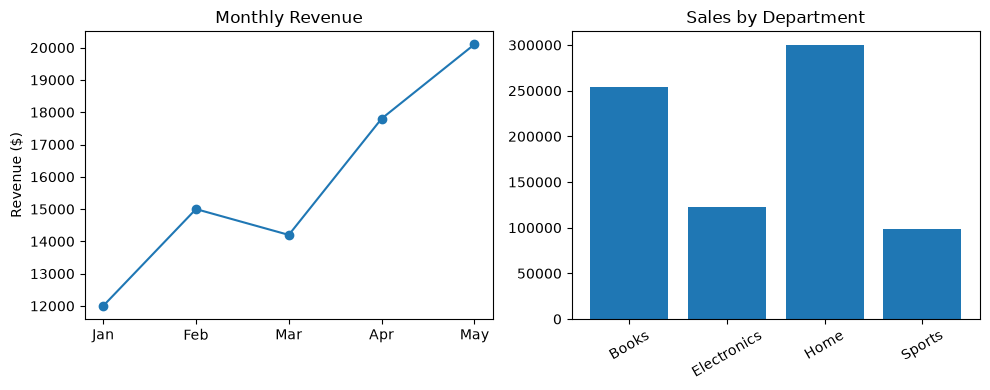

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))   # 1 row, 2 columns; figsize in inches

axes[0].plot(months, revenue, marker='o')
axes[0].set_title('Monthly Revenue')
axes[0].set_ylabel('Revenue ($)')

axes[1].bar(departments, sales)
axes[1].set_title('Sales by Department')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()   # stops the titles and labels from overlapping
plt.show()

✅ **Your Turn**: Create a figure with two subplots side by side: a line chart of `revenue` by month on the left, and a histogram of 50 made-up individual purchase amounts on the right (try `np.random.normal(40, 12, size=50)`). Give each subplot a title.

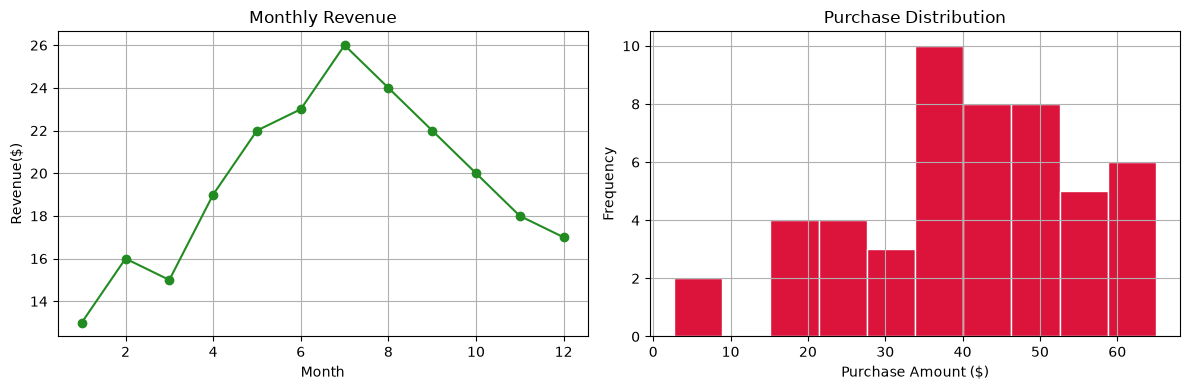

In [31]:
# Your turn here
my_months = np.arange(1, 13)
my_revenue = np.array([13, 16, 15, 19, 22, 23, 26, 24, 22, 20, 18, 17])

purchases = np.random.normal(40, 12, size=50)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Line chart
axes[0].plot(my_months, my_revenue, marker='o', color='forestgreen')
axes[0].set_title('Monthly Revenue')
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Revenue($)')
axes[0].grid(True)

# Histogram
axes[1].hist(purchases, bins=10, color='crimson', edgecolor='white')
axes[1].set_title('Purchase Distribution')
axes[1].set_xlabel('Purchase Amount ($)')
axes[1].set_ylabel('Frequency')
axes[1].grid(True)

plt.tight_layout()
plt.show()


## 11. Choosing the Right Chart
Start from the **question**, not the chart type:

| The question is about... | Use a... |
|---|---|
| Change over time or another ordered value | Line plot |
| Comparing amounts across categories | Bar chart (`barh` for long labels) |
| A relationship between two numeric variables | Scatter plot |
| The distribution of one numeric variable | Histogram |
| Comparing distributions across groups, or finding outliers | Box plot |
| Parts of one whole, with only a few categories | Pie chart (but consider a bar chart) |

✅ **Your Turn**: Double-click the cell below and choose the best chart for each question, with a one-line reason for each.
1. Which department generated the most revenue?
2. How did daily website visits change over a month?
3. Is there a relationship between product price and units sold?
4. What is the distribution of customer order values?
5. How do exam-score distributions compare across three course sections?

*Your answers here.*
1. **Bar Chart** - comparing separate department categories
2. **Line Plot** - changing number of visits over time
3. **Scatter Plot** - checking for relationship between price and units sold
4. **Histogram** - you want the distribution of one numeric variable, that being customer order value
5. **Box Plot** - comparing distribution of exam=scores across groups

## 12. Saving a Chart
`plt.savefig` writes the current figure to an image file:
- `dpi` sets the resolution. 300 is print quality, and around 100 is fine for screens.
- `bbox_inches='tight'` trims extra white space around the edges.
- The file extension picks the format: `.png`, `.jpg`, `.svg`, or `.pdf`.

⚠️ Call `savefig` **before** `plt.show()`. `plt.show()` finishes the figure and clears it, so saving afterwards gives you a **blank** image.

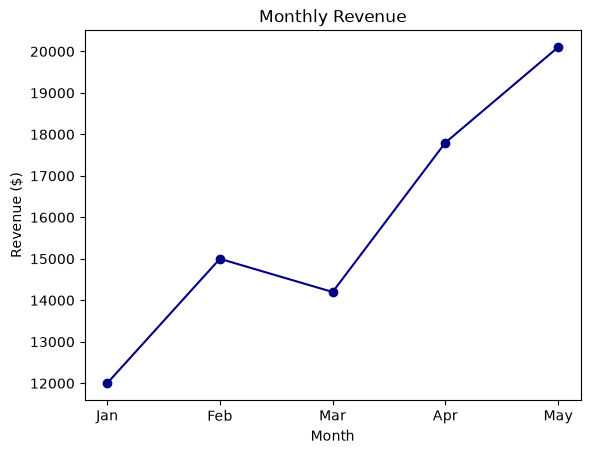

Saved: 07-OutputFiles\monthly_revenue.png


In [32]:
plt.plot(months, revenue, marker='o', color='navy')
plt.title('Monthly Revenue')
plt.xlabel('Month')
plt.ylabel('Revenue ($)')

plt.savefig(OUT / 'monthly_revenue.png', dpi=300, bbox_inches='tight')
plt.show()

print('Saved:', OUT / 'monthly_revenue.png')

With subplots, call `fig.savefig(...)` to save the whole figure.

✅ **Your Turn**: Save one of the charts you made earlier (your favorite) to `OUT / 'my_chart.png'`. Then embed it in the Markdown cell below with `![My chart](07-OutputFiles/my_chart.png)` (see notebook 04).

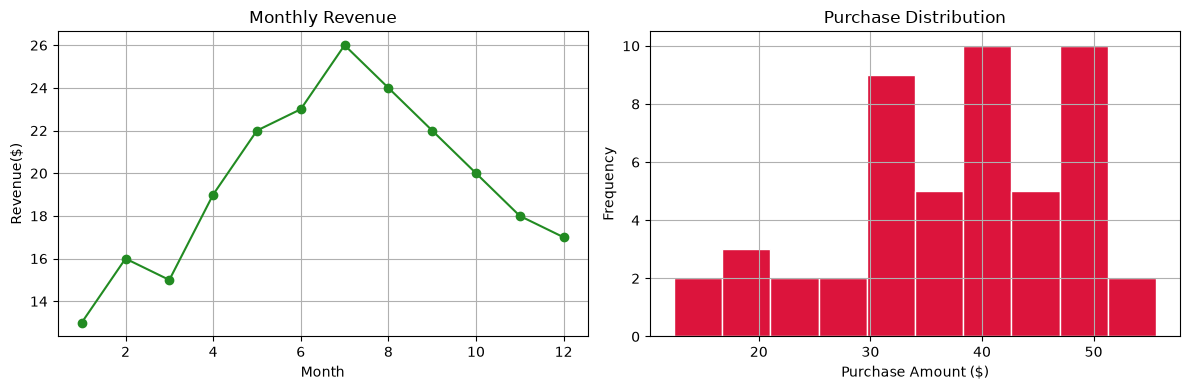

Saved: 07-OutputFiles\my_chart.png


In [33]:
# Your turn here
my_months = np.arange(1, 13)
my_revenue = np.array([13, 16, 15, 19, 22, 23, 26, 24, 22, 20, 18, 17])

purchases = np.random.normal(40, 12, size=50)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Line chart
axes[0].plot(my_months, my_revenue, marker='o', color='forestgreen')
axes[0].set_title('Monthly Revenue')
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Revenue($)')
axes[0].grid(True)

# Histogram
axes[1].hist(purchases, bins=10, color='crimson', edgecolor='white')
axes[1].set_title('Purchase Distribution')
axes[1].set_xlabel('Purchase Amount ($)')
axes[1].set_ylabel('Frequency')
axes[1].grid(True)

plt.tight_layout()

plt.savefig(OUT / 'my_chart.png', dpi=300, bbox_inches='tight')
plt.show()

print('Saved:', OUT / 'my_chart.png')

![My chart](07-OutputFiles\my_chart.png)

## 13. Chart-Quality Checklist
Before sharing a figure, ask:
- [ ] Does the chart type fit the question? (See section 11.)
- [ ] Does it have a useful title?
- [ ] Are both axes labeled, **including units**?
- [ ] Is the scale honest and readable? A bar chart's y-axis should start at **0**, or small differences look huge.
- [ ] Does color add meaning, rather than decoration?
- [ ] Is a legend needed, and is it there?
- [ ] Could someone understand the chart **without reading the code**?

---
### Summary
- NumPy arrays do math on every element at once. `arange`, `linspace`, and `np.random` generate data, and `mean`/`median`/`min`/`max` summarize it.
- Every chart follows the same pattern: plot, then title and label (with units), then show. Style the data with `color`, `marker`, and `linestyle`.
- **Line** = change over time. **Bar** = compare categories. **Scatter** = relationship. **Histogram** = distribution. **Box** = compare distributions and spot outliers. **Pie** = parts of a whole (sparingly).
- `fig, axes = plt.subplots(rows, cols)` puts several charts in one figure. Use the `ax.set_...` methods there.
- `plt.savefig(..., dpi=300, bbox_inches='tight')` goes **before** `plt.show()`.
- Pick the chart from the question, and check it against the quality checklist before you share it.

## 🏋️ Practice

### Practice 1 — Sorted Bar Chart from a Dictionary (easy)
Given `pet_counts = {'Dogs': 12, 'Cats': 9, 'Birds': 3, 'Fish': 5}`, build a bar chart from it directly (hint: `.keys()` and `.values()`). Then make a second version with the bars **sorted from highest to lowest**. Hint: `sorted(pet_counts, key=pet_counts.get, reverse=True)` gives you the keys in that order.

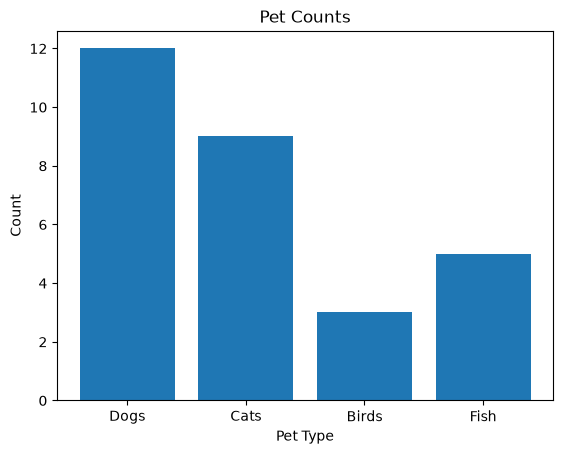

In [34]:
pet_counts = {'Dogs': 12, 'Cats': 9, 'Birds': 3, 'Fish': 5}
# Your code here
plt.bar(pet_counts.keys(), pet_counts.values())
plt.title("Pet Counts")
plt.xlabel("Pet Type")
plt.ylabel("Count")
plt.show()

### Practice 2 — Two Lines, One Legend (medium)
Plot `y = x` and `y = x**2` on the same axes for `x = np.linspace(0, 5, 50)`, with a legend distinguishing them and a title.

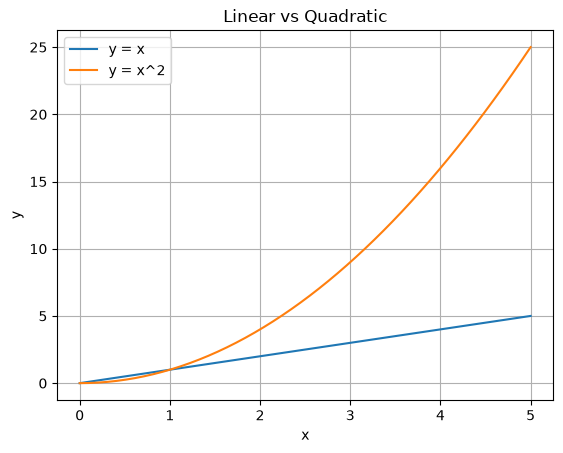

In [35]:
# Your code here
x = np.linspace(0, 5, 50)

plt.plot(x, x, label='y = x')
plt.plot(x, x**2, label='y = x^2')

plt.title('Linear vs Quadratic')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid(True)
plt.show()

### Practice 3 — Fix a Bad Chart (harder)
The chart below breaks several rules from the checklist in section 13. Run it, then:
1. In a Markdown cell, list **every** problem you can find. *Hint:* look closely at the y-axis. The four teams' win totals are actually very close.
2. In a new code cell, draw a clear, honest version.
3. Explain in one or two sentences what changed, and why the original was misleading.

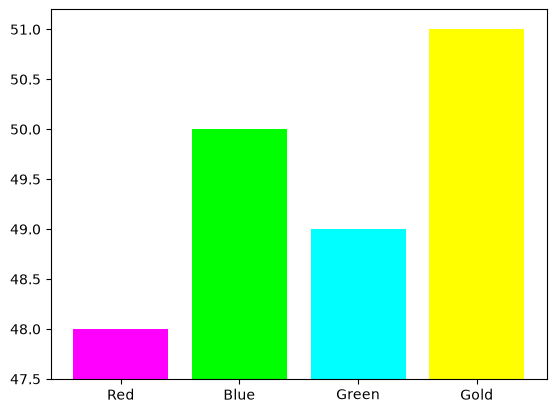

In [36]:
teams = ['Red', 'Blue', 'Green', 'Gold']
wins = [48, 50, 49, 51]

plt.bar(teams, wins, color=['magenta', 'lime', 'cyan', 'yellow'])
plt.ylim(47.5, 51.2)
plt.show()

*Your list of problems here.*
1. No title
2. No axes labeled
3. Scale not honest (Starts at 47.5 instead of 0)
4. Color has no meaning
5. Chart not understandable without code

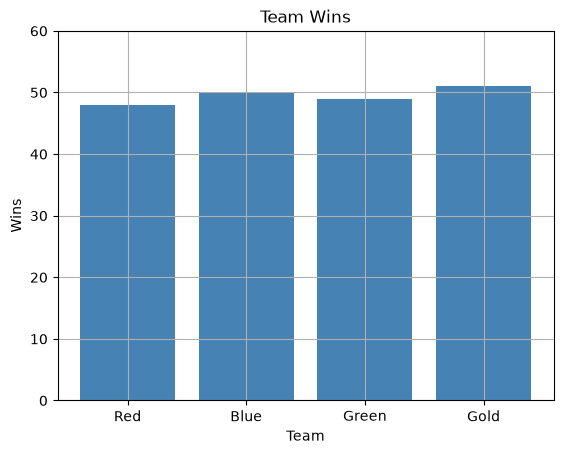

In [37]:
# Your improved chart here
teams = ['Red', 'Blue', 'Green', 'Gold']
wins = [48, 50, 49, 51]

plt.bar(teams, wins, color='steelblue')
plt.title("Team Wins")
plt.xlabel("Team")
plt.ylabel("Wins")
plt.ylim(0, 60)
plt.grid(True)

plt.show()

**What Changed:** A title and labels were added, the scale was changed to start at 0, and the color was changed. The original was misleading because the scale started at 47.5 instead of 0, making the difference in wins seem much larger than they really are.

## 🔥 Challenge (Optional) — Store Sales Dashboard
The cell below generates a fictional month of sales for a small store, with the columns `date`, `department`, `sales_amount`, `units_sold`, and `customer_rating`, and saves it with Pandas (notebook 06). Use it to create:
1. A **line chart** of total sales per day. *Hint:* `daily = store.groupby('date')['sales_amount'].sum()` adds up each day's sales. Then plot `daily.index` vs `daily.values`.
2. A **bar chart** of total sales by department (use `groupby('department')` the same way).
3. A **scatter plot** of units sold versus customer rating.
4. A **histogram** of individual purchase amounts.
5. **One figure** with at least two of these as subplots. Save it to `OUT / 'store_dashboard.png'`.
6. In a Markdown cell, a short written explanation of the **most useful finding** from your charts.

In [38]:
import pandas as pd

np.random.seed(3603)
n = 120   # 4 purchases a day for 30 days
store = pd.DataFrame({
    'date': np.repeat(pd.date_range('2026-09-01', periods=30), 4),
    'department': np.random.choice(['Books', 'Electronics', 'Home', 'Sports'], size=n),
    'units_sold': np.random.randint(1, 6, size=n),
    'customer_rating': np.clip(np.random.normal(4, 0.7, size=n), 1, 5).round(1),
})
store['sales_amount'] = (store['units_sold'] * np.random.uniform(10, 60, size=n)).round(2)
store.to_csv(OUT / 'store_sales.csv', index=False)
store.head()

# Your code here

,date,department,units_sold,customer_rating,sales_amount
0,2026-09-01,Electronics,5,4.1,102.06
1,2026-09-01,Home,4,3.6,194.83
2,2026-09-01,Sports,3,3.2,132.54
3,2026-09-01,Electronics,2,3.2,63.53
4,2026-09-02,Electronics,4,3.6,44.33


*Your most useful finding here.*

## 📦 Check Your Output Files
Run this last to see everything you created. All of it should be inside `07-OutputFiles`. Upload that folder along with this notebook.

In [39]:
for path in sorted(OUT.rglob('*')):
    print(path)

07-OutputFiles\monthly_revenue.png
07-OutputFiles\my_chart.png
07-OutputFiles\store_sales.csv
